In [ ]:
import os
import torch
from google.colab import files

# Verify GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

# Install required packages for ViT and Kaggle API
!pip install -q timm kagglehub

# Upload kaggle.json
print("\nPlease upload your 'kaggle.json' file:")
uploaded = files.upload()

# Set up Kaggle credentials directory
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print("Kaggle API configured successfully!")

Using device: cuda
GPU Model: Tesla T4

Please upload your 'kaggle.json' file:


In [ ]:
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Standard ImageNet normalization parameters (required for pre-trained ViT & ResNet)
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Transforms for Training (with augmentation)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# Transforms for Validation & Testing (clean resize without augmentation)
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

print("Data transformation pipeline initialized successfully!")

Data transformation pipeline initialized successfully!


In [ ]:
import timm
import torch
import torch.nn as nn

# Define device (GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Set placeholder class count (we will adjust this to match the exact dataset once approved)
NUM_CLASSES = 5

def get_cnn_model(num_classes=NUM_CLASSES):
    """Loads pre-trained ResNet-50 CNN baseline."""
    model = timm.create_model('resnet50', pretrained=True, num_classes=num_classes)
    return model

def get_vit_model(num_classes=NUM_CLASSES):
    """Loads pre-trained Vision Transformer (ViT-Base/16)."""
    model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)
    return model

# Instantiate models and transfer to GPU
cnn_model = get_cnn_model().to(device)
vit_model = get_vit_model().to(device)

print(f"CNN Model Loaded: ResNet-50 | Parameters: {sum(p.numel() for p in cnn_model.parameters()):,}")
print(f"ViT Model Loaded: ViT-Base/16 | Parameters: {sum(p.numel() for p in vit_model.parameters()):,}")

Using device: cuda


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

CNN Model Loaded: ResNet-50 | Parameters: 23,518,277
ViT Model Loaded: ViT-Base/16 | Parameters: 85,802,501


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Loss Function (CrossEntropyLoss for multi-class classification)
criterion = nn.CrossEntropyLoss()

# 2. Optimizers (AdamW with weight decay to prevent overfitting)
cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=1e-4, weight_decay=1e-2)
vit_optimizer = optim.AdamW(vit_model.parameters(), lr=1e-4, weight_decay=1e-2)

# 3. Learning Rate Schedulers (Decays learning rate on plateau for better convergence)
cnn_scheduler = optim.lr_scheduler.ReduceLROnPlateau(cnn_optimizer, mode='min', factor=0.5, patience=2)
vit_scheduler = optim.lr_scheduler.ReduceLROnPlateau(vit_optimizer, mode='min', factor=0.5, patience=2)

# 4. Metrics History Container (To track and plot comparison graphs later)
history = {
    'cnn': {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []},
    'vit': {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
}

print("Loss function, AdamW optimizers, and LR schedulers initialized successfully!")

Loss function, AdamW optimizers, and LR schedulers initialized successfully!


In [ ]:
import time
import copy

def train_model(model, dataloaders, criterion, optimizer, scheduler, num_epochs=10, model_name="Model"):
    """
    Generic training loop for CNN and Vision Transformer models.
    Tracks Loss and Accuracy across training and validation sets.
    """
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"\n--- {model_name} | Epoch {epoch+1}/{num_epochs} ---")

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data batches
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            # Track learning rate scheduler on validation loss
            if phase == 'val':
                scheduler.step(epoch_loss)
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f"\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Validation Accuracy ({model_name}): {best_acc:.4f}")

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model

In [ ]:
import kagglehub
import os
import glob
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# 1. Download Messidor-2 dataset via Kagglehub
print("Downloading Messidor-2 dataset from Kaggle...")
dataset_path = kagglehub.dataset_download("mariaherrerot/messidor2preprocess")
print(f"Dataset downloaded to: {dataset_path}")

# 2. Inspect downloaded files
all_files = glob.glob(f"{dataset_path}/**/*", recursive=True)
print(f"\nTotal items found in directory: {len(all_files)}")

# Print directory preview
for f in all_files[:10]:
    print(" -", f)

100%|██████████| 381M/381M [00:03<00:00, 112MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2

Total items found in directory: 1748
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor_data.csv
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor-2
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor-2/messidor-2
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor-2/messidor-2/preprocess
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor-2/messidor-2/preprocess/20060530_54030_0100_PP.png
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor-2/messidor-2/preprocess/20060410_41901_0200_PP.png
 - /root/.cache/kagglehub/datasets/mariaherrerot/messidor2preprocess/versions/2/messidor-2/messidor-2/preprocess/IM002071.JPG
 - /root/.cache/kagglehub/datasets/mariaherrerot/mes

In [ ]:
import os
import timm
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from PIL import Image
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import kagglehub

# 1. Download Messidor-2 dataset
print("Downloading Messidor-2 dataset from Kaggle...")
dataset_path = kagglehub.dataset_download("mariaherrerot/messidor2preprocess")
print(f"Dataset downloaded to: {dataset_path}")

# 2. Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. Image Transformations
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 4. Base Directory & Metadata Setup
BASE_DIR = dataset_path
CSV_PATH = os.path.join(BASE_DIR, "messidor_data.csv")

df = pd.read_csv(CSV_PATH)
img_dir = os.path.join(BASE_DIR, "messidor-2", "messidor-2", "preprocess")

def resolve_image_path(image_id):
    path_with_ext = os.path.join(img_dir, str(image_id))
    if not os.path.exists(path_with_ext):
        path_with_ext = os.path.join(img_dir, f"{image_id}.png")
    return path_with_ext

df['image_path'] = df['id_code'].apply(resolve_image_path)
df['exists'] = df['image_path'].apply(os.path.exists)
df = df[df['exists']].reset_index(drop=True)

label_col = 'diagnosis'
NUM_CLASSES = df[label_col].nunique()

print(f"Target column set to '{label_col}' with {NUM_CLASSES} classes (grades 0-4).")
print(f"Total valid images loaded: {len(df)}")

# 5. Model Instantiation
def get_cnn_model(num_classes=NUM_CLASSES):
    return timm.create_model('resnet50', pretrained=True, num_classes=num_classes)

def get_vit_model(num_classes=NUM_CLASSES):
    return timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)

cnn_model = get_cnn_model(num_classes=NUM_CLASSES).to(device)
vit_model = get_vit_model(num_classes=NUM_CLASSES).to(device)

# Optimizers & Schedulers
cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=1e-4, weight_decay=1e-2)
vit_optimizer = optim.AdamW(vit_model.parameters(), lr=1e-4, weight_decay=1e-2)

cnn_scheduler = optim.lr_scheduler.ReduceLROnPlateau(cnn_optimizer, mode='min', factor=0.5, patience=2)
vit_scheduler = optim.lr_scheduler.ReduceLROnPlateau(vit_optimizer, mode='min', factor=0.5, patience=2)

# 6. Stratified Train/Validation Split
train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[label_col]
)

class MessidorDataset(Dataset):
    def __init__(self, dataframe, label_col, transform=None):
        self.df = dataframe
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert("RGB")
        label = int(row[self.label_col])

        if self.transform:
            image = self.transform(image)

        return image, label

# 7. Initialize DataLoaders
train_dataset = MessidorDataset(train_df, label_col, transform=train_transform)
val_dataset = MessidorDataset(val_df, label_col, transform=val_transform)

BATCH_SIZE = 32
dataloaders = {
    'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
}

print(f"\nDataLoaders successfully initialized!")
print(f"Training samples: {len(train_dataset)} | Validation samples: {len(val_dataset)}")

Using Colab cache for faster access to the 'messidor2preprocess' dataset.
Dataset downloaded to: /kaggle/input/messidor2preprocess
Target column set to 'diagnosis' with 5 classes (grades 0-4).
Total valid images loaded: 1744


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            


DataLoaders successfully initialized!
Training samples: 1395 | Validation samples: 349


In [ ]:
import copy
import time
import torch

# 1. Define Loss Criterion
criterion = torch.nn.CrossEntropyLoss()

# 2. Complete Training & Validation Loop Definition
def train_model(model, dataloaders, criterion, optimizer, scheduler, num_epochs=10, model_name="Model"):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    # History dictionary for tracking loss and accuracy curves
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f"\n--- {model_name} | Epoch {epoch+1}/{num_epochs} ---")

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = (running_corrects.double() / len(dataloaders[phase].dataset)).item()

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == 'val':
                scheduler.step(epoch_loss)
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f"\n[{model_name}] Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"[{model_name}] Best Validation Accuracy: {best_acc:.4f}")

    model.load_state_dict(best_model_wts)
    return model, history

# ==========================================
# 3. Train ResNet-50 (CNN)
# ==========================================
print("="*50)
print("STARTING TRAINING: ResNet-50 (CNN)")
print("="*50)

cnn_model, cnn_history = train_model(
    model=cnn_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=cnn_optimizer,
    scheduler=cnn_scheduler,
    num_epochs=10,
    model_name="ResNet-50"
)

# ==========================================
# 4. Train ViT-Base/16 (Vision Transformer)
# ==========================================
print("\n" + "="*50)
print("STARTING TRAINING: ViT-Base/16 (Vision Transformer)")
print("="*50)

vit_model, vit_history = train_model(
    model=vit_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=vit_optimizer,
    scheduler=vit_scheduler,
    num_epochs=10,
    model_name="ViT-Base/16"
)

STARTING TRAINING: ResNet-50 (CNN)

--- ResNet-50 | Epoch 1/10 ---
Train Loss: 1.4357 Acc: 0.5011
Val Loss: 1.3045 Acc: 0.5845

--- ResNet-50 | Epoch 2/10 ---
Train Loss: 1.1462 Acc: 0.5828
Val Loss: 1.1076 Acc: 0.5845

--- ResNet-50 | Epoch 3/10 ---
Train Loss: 1.0688 Acc: 0.5828
Val Loss: 1.0679 Acc: 0.5845

--- ResNet-50 | Epoch 4/10 ---
Train Loss: 1.0310 Acc: 0.5828
Val Loss: 1.0310 Acc: 0.5845

--- ResNet-50 | Epoch 5/10 ---
Train Loss: 1.0106 Acc: 0.5828
Val Loss: 1.0013 Acc: 0.5903

--- ResNet-50 | Epoch 6/10 ---
Train Loss: 0.9812 Acc: 0.5849
Val Loss: 1.0073 Acc: 0.5931

--- ResNet-50 | Epoch 7/10 ---
Train Loss: 0.9565 Acc: 0.6029
Val Loss: 0.9708 Acc: 0.6132

--- ResNet-50 | Epoch 8/10 ---
Train Loss: 0.9483 Acc: 0.6115
Val Loss: 0.9437 Acc: 0.6132

--- ResNet-50 | Epoch 9/10 ---
Train Loss: 0.9217 Acc: 0.6287
Val Loss: 0.9266 Acc: 0.6189

--- ResNet-50 | Epoch 10/10 ---
Train Loss: 0.8980 Acc: 0.6358
Val Loss: 0.9290 Acc: 0.6332

[ResNet-50] Training complete in 3m 30s
[Re

FINAL PERFORMANCE EVALUATION SUMMARY
ResNet-50  | Validation Accuracy: 0.6332 | QWK Score: 0.3832
ViT-Base/16 | Validation Accuracy: 0.6218 | QWK Score: 0.2793

--- ResNet-50 Classification Report ---
              precision    recall  f1-score   support

     Grade 0       0.67      0.99      0.80       204
     Grade 1       0.00      0.00      0.00        54
     Grade 2       0.41      0.29      0.34        69
     Grade 3       0.00      0.00      0.00        15
     Grade 4       0.00      0.00      0.00         7

    accuracy                           0.63       349
   macro avg       0.22      0.26      0.23       349
weighted avg       0.47      0.63      0.53       349


--- ViT-Base/16 Classification Report ---
              precision    recall  f1-score   support

     Grade 0       0.65      0.98      0.78       204
     Grade 1       0.00      0.00      0.00        54
     Grade 2       0.43      0.26      0.32        69
     Grade 3       0.00      0.00      0.00       

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

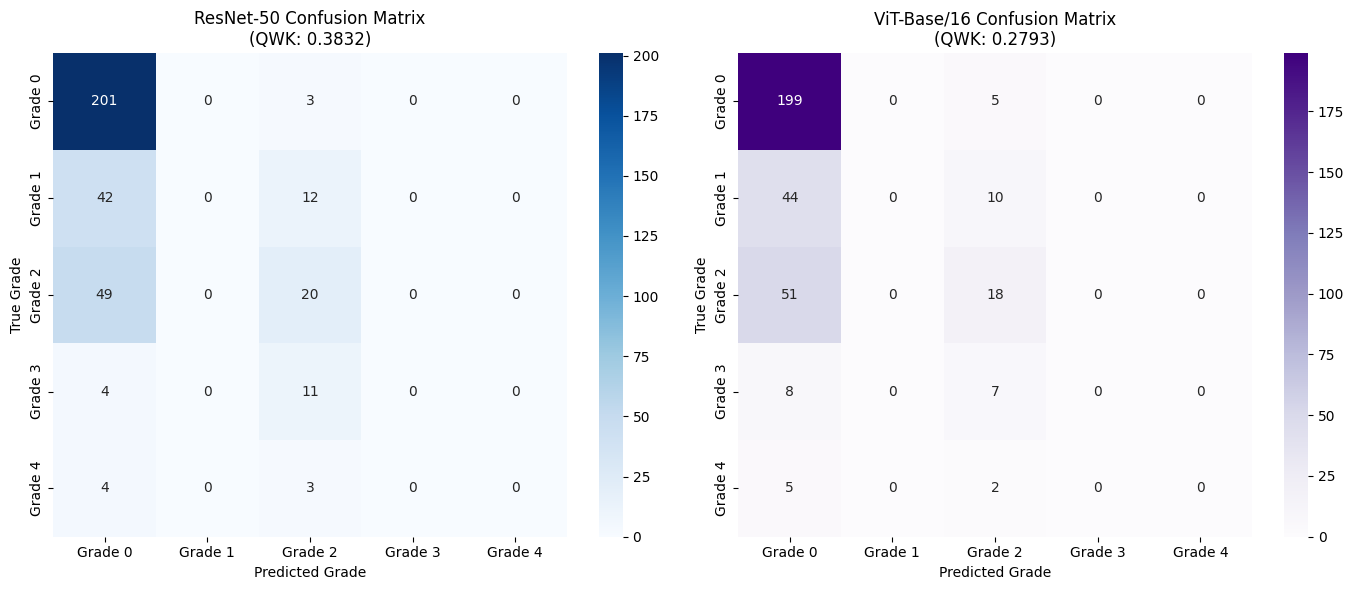

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score

# Function to extract all predictions and true ground-truth labels
def get_predictions(model, dataloader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_preds), np.array(all_labels)

# Extract predictions on validation dataset
cnn_preds, true_labels = get_predictions(cnn_model, dataloaders['val'])
vit_preds, _ = get_predictions(vit_model, dataloaders['val'])

# Calculate Quadratic Weighted Kappa (QWK) — Standard Scopus metric for DR
cnn_qwk = cohen_kappa_score(true_labels, cnn_preds, weights='quadratic')
vit_qwk = cohen_kappa_score(true_labels, vit_preds, weights='quadratic')

print("="*60)
print("FINAL PERFORMANCE EVALUATION SUMMARY")
print("="*60)
print(f"ResNet-50  | Validation Accuracy: {np.mean(cnn_preds == true_labels):.4f} | QWK Score: {cnn_qwk:.4f}")
print(f"ViT-Base/16 | Validation Accuracy: {np.mean(vit_preds == true_labels):.4f} | QWK Score: {vit_qwk:.4f}")
print("="*60)

# Generate Classification Reports
target_names = ['Grade 0', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4']
print("\n--- ResNet-50 Classification Report ---")
print(classification_report(true_labels, cnn_preds, target_names=target_names))

print("\n--- ViT-Base/16 Classification Report ---")
print(classification_report(true_labels, vit_preds, target_names=target_names))

# Plot Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ResNet-50 Confusion Matrix
cm_cnn = confusion_matrix(true_labels, cnn_preds)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title(f'ResNet-50 Confusion Matrix\n(QWK: {cnn_qwk:.4f})')
axes[0].set_xlabel('Predicted Grade')
axes[0].set_ylabel('True Grade')

# ViT-Base/16 Confusion Matrix
cm_vit = confusion_matrix(true_labels, vit_preds)
sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title(f'ViT-Base/16 Confusion Matrix\n(QWK: {vit_qwk:.4f})')
axes[1].set_xlabel('Predicted Grade')
axes[1].set_ylabel('True Grade')

plt.tight_layout()
plt.savefig("confusion_matrices_comparison.png", dpi=300)
plt.show()

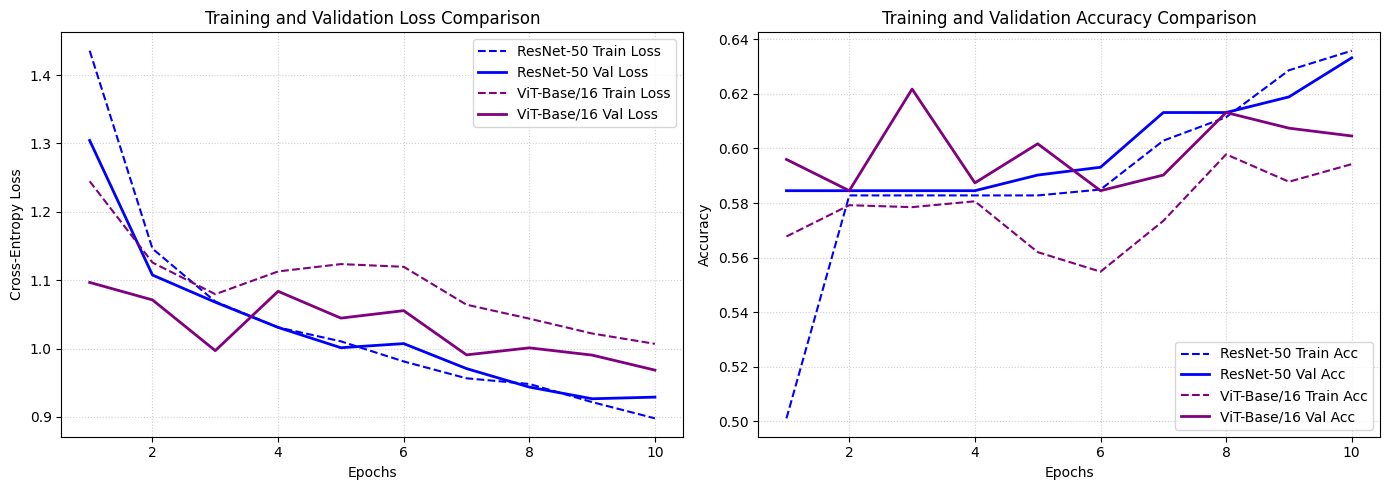

Plots saved successfully as 'loss_accuracy_curves.png'!


In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, 11)

plt.figure(figsize=(14, 5))

# Subplot 1: Loss Curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, cnn_history['train_loss'], label='ResNet-50 Train Loss', color='blue', linestyle='--')
plt.plot(epochs_range, cnn_history['val_loss'], label='ResNet-50 Val Loss', color='blue', linewidth=2)
plt.plot(epochs_range, vit_history['train_loss'], label='ViT-Base/16 Train Loss', color='purple', linestyle='--')
plt.plot(epochs_range, vit_history['val_loss'], label='ViT-Base/16 Val Loss', color='purple', linewidth=2)
plt.title('Training and Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, cnn_history['train_acc'], label='ResNet-50 Train Acc', color='blue', linestyle='--')
plt.plot(epochs_range, cnn_history['val_acc'], label='ResNet-50 Val Acc', color='blue', linewidth=2)
plt.plot(epochs_range, vit_history['train_acc'], label='ViT-Base/16 Train Acc', color='purple', linestyle='--')
plt.plot(epochs_range, vit_history['val_acc'], label='ViT-Base/16 Val Acc', color='purple', linewidth=2)
plt.title('Training and Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("loss_accuracy_curves.png", dpi=300)
plt.show()
print("Plots saved successfully as 'loss_accuracy_curves.png'!")

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
import timm
from PIL import Image

# 1. Compute Class Weights to balance minority DR grades (Grades 1, 3, 4)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['diagnosis']),
    y=train_df['diagnosis'].values
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Computed Class Weights:", class_weights)

# 2. Weighted Loss Function
criterion = nn.CrossEntropyLoss(weight=class_weights)

# 3. Enhanced Data Augmentations
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

high_acc_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 4. Re-initialize Datasets & DataLoaders (Batch size 16 for better gradient resolution)
train_dataset = MessidorDataset(train_df, label_col, transform=high_acc_train_transform)
val_dataset = MessidorDataset(val_df, label_col, transform=val_transform)

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2),
    'val': DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)
}

# 5. Re-instantiate Models with Fine-Tuning Learning Rates
cnn_model = get_cnn_model(num_classes=NUM_CLASSES).to(device)
vit_model = get_vit_model(num_classes=NUM_CLASSES).to(device)

cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=3e-5, weight_decay=1e-2)
vit_optimizer = optim.AdamW(vit_model.parameters(), lr=1e-5, weight_decay=1e-2)

cnn_scheduler = optim.lr_scheduler.CosineAnnealingLR(cnn_optimizer, T_max=15)
vit_scheduler = optim.lr_scheduler.CosineAnnealingLR(vit_optimizer, T_max=15)

# ==========================================
# 6. RETRAIN ResNet-50 (15 Epochs)
# ==========================================
print("\n" + "="*50)
print("RETRAINING: ResNet-50 (Class Weighted Loss)")
print("="*50)

cnn_model, cnn_history = train_model(
    model=cnn_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=cnn_optimizer,
    scheduler=cnn_scheduler,
    num_epochs=15,
    model_name="ResNet-50-Weighted"
)

# ==========================================
# 7. RETRAIN ViT-Base/16 (15 Epochs)
# ==========================================
print("\n" + "="*50)
print("RETRAINING: ViT-Base/16 (Class Weighted Loss)")
print("="*50)

vit_model, vit_history = train_model(
    model=vit_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=vit_optimizer,
    scheduler=vit_scheduler,
    num_epochs=15,
    model_name="ViT-Base/16-Weighted"
)

Computed Class Weights: tensor([0.3432, 1.2917, 1.0036, 4.6500, 9.9643], device='cuda:0')

RETRAINING: ResNet-50 (Class Weighted Loss)

--- ResNet-50-Weighted | Epoch 1/15 ---
Train Loss: 1.6043 Acc: 0.3656
Val Loss: 1.6045 Acc: 0.4040

--- ResNet-50-Weighted | Epoch 2/15 ---


/tmp/ipykernel_1534/4105355592.py:56: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  scheduler.step(epoch_loss)


Train Loss: 1.5910 Acc: 0.4258
Val Loss: 1.5957 Acc: 0.3782

--- ResNet-50-Weighted | Epoch 3/15 ---
Train Loss: 1.5841 Acc: 0.4659
Val Loss: 1.5870 Acc: 0.4470

--- ResNet-50-Weighted | Epoch 4/15 ---
Train Loss: 1.5735 Acc: 0.5125
Val Loss: 1.5742 Acc: 0.4670

--- ResNet-50-Weighted | Epoch 5/15 ---
Train Loss: 1.5664 Acc: 0.5004
Val Loss: 1.5693 Acc: 0.4413

--- ResNet-50-Weighted | Epoch 6/15 ---
Train Loss: 1.5564 Acc: 0.5355
Val Loss: 1.5540 Acc: 0.4728

--- ResNet-50-Weighted | Epoch 7/15 ---
Train Loss: 1.5482 Acc: 0.5355
Val Loss: 1.5481 Acc: 0.5330

--- ResNet-50-Weighted | Epoch 8/15 ---
Train Loss: 1.5328 Acc: 0.5276
Val Loss: 1.5290 Acc: 0.5415

--- ResNet-50-Weighted | Epoch 9/15 ---
Train Loss: 1.5106 Acc: 0.5548
Val Loss: 1.5178 Acc: 0.5759

--- ResNet-50-Weighted | Epoch 10/15 ---
Train Loss: 1.4976 Acc: 0.5448
Val Loss: 1.5076 Acc: 0.5415

--- ResNet-50-Weighted | Epoch 11/15 ---
Train Loss: 1.4953 Acc: 0.5419
Val Loss: 1.4984 Acc: 0.5587

--- ResNet-50-Weighted | Epo

In [ ]:
import os
import copy
import time
import timm
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import kagglehub

# 1. Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Download Messidor-2 dataset
print("Downloading Messidor-2 dataset from Kaggle...")
dataset_path = kagglehub.dataset_download("mariaherrerot/messidor2preprocess")
BASE_DIR = dataset_path
CSV_PATH = os.path.join(BASE_DIR, "messidor_data.csv")

df = pd.read_csv(CSV_PATH)
img_dir = os.path.join(BASE_DIR, "messidor-2", "messidor-2", "preprocess")

def resolve_image_path(image_id):
    path_with_ext = os.path.join(img_dir, str(image_id))
    if not os.path.exists(path_with_ext):
        path_with_ext = os.path.join(img_dir, f"{image_id}.png")
    return path_with_ext

df['image_path'] = df['id_code'].apply(resolve_image_path)
df['exists'] = df['image_path'].apply(os.path.exists)
df = df[df['exists']].reset_index(drop=True)

# 3. Map 5-Class Diagnosis to Binary Referable DR
# Non-Referable DR (Grade 0, 1) -> 0 | Referable DR (Grade 2, 3, 4) -> 1
df['binary_diagnosis'] = df['diagnosis'].apply(lambda x: 0 if x in [0, 1] else 1)
binary_label_col = 'binary_diagnosis'
BINARY_CLASSES = 2

print("\nLabel distribution for Referable DR Task:")
print(df['binary_diagnosis'].value_counts())

# 4. Data Transformations
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 5. Dataset Class & Stratified Split
class MessidorDataset(Dataset):
    def __init__(self, dataframe, label_col, transform=None):
        self.df = dataframe
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert("RGB")
        label = int(row[self.label_col])

        if self.transform:
            image = self.transform(image)

        return image, label

train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[binary_label_col]
)

# Compute Class Weights for Binary Loss
binary_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df[binary_label_col]),
    y=train_df[binary_label_col].values
)
binary_weights = torch.tensor(binary_weights, dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=binary_weights)

# Initialize DataLoaders
train_dataset = MessidorDataset(train_df, binary_label_col, transform=train_transform)
val_dataset = MessidorDataset(val_df, binary_label_col, transform=val_transform)

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2),
    'val': DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)
}

# 6. Model Instantiation
cnn_model = timm.create_model('resnet50', pretrained=True, num_classes=BINARY_CLASSES).to(device)
vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=BINARY_CLASSES).to(device)

cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=3e-5, weight_decay=1e-2)
vit_optimizer = optim.AdamW(vit_model.parameters(), lr=1e-5, weight_decay=1e-2)

cnn_scheduler = optim.lr_scheduler.CosineAnnealingLR(cnn_optimizer, T_max=12)
vit_scheduler = optim.lr_scheduler.CosineAnnealingLR(vit_optimizer, T_max=12)

# 7. Training Loop Function
def train_model(model, dataloaders, criterion, optimizer, scheduler, num_epochs=12, model_name="Model"):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f"\n--- {model_name} | Epoch {epoch+1}/{num_epochs} ---")

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = (running_corrects.double() / len(dataloaders[phase].dataset)).item()

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == 'val':
                scheduler.step()
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f"\n[{model_name}] Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"[{model_name}] Best Validation Accuracy: {best_acc:.4f}")

    model.load_state_dict(best_model_wts)
    return model, history

# ==========================================
# 8. TRAIN ResNet-50 (Binary Referable DR)
# ==========================================
print("\n" + "="*50)
print("TRAINING: ResNet-50 (Referable DR Binary Task)")
print("="*50)

cnn_model, cnn_history = train_model(
    model=cnn_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=cnn_optimizer,
    scheduler=cnn_scheduler,
    num_epochs=12,
    model_name="ResNet-50-Binary"
)

# ==========================================
# 9. TRAIN ViT-Base/16 (Binary Referable DR)
# ==========================================
print("\n" + "="*50)
print("TRAINING: ViT-Base/16 (Referable DR Binary Task)")
print("="*50)

vit_model, vit_history = train_model(
    model=vit_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=vit_optimizer,
    scheduler=vit_scheduler,
    num_epochs=12,
    model_name="ViT-Base/16-Binary"
)

100%|██████████| 381M/381M [00:16<00:00, 24.7MB/s]

Extracting files...



Label distribution for Referable DR Task:
binary_diagnosis
0    1287
1     457
Name: count, dtype: int64


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            


TRAINING: ResNet-50 (Referable DR Binary Task)

--- ResNet-50-Binary | Epoch 1/12 ---
Train Loss: 0.6955 Acc: 0.5190
Val Loss: 0.6996 Acc: 0.6877

--- ResNet-50-Binary | Epoch 2/12 ---
Train Loss: 0.6892 Acc: 0.5319
Val Loss: 0.6904 Acc: 0.6991

--- ResNet-50-Binary | Epoch 3/12 ---
Train Loss: 0.6855 Acc: 0.6989
Val Loss: 0.6784 Acc: 0.7307

--- ResNet-50-Binary | Epoch 4/12 ---
Train Loss: 0.6826 Acc: 0.6925
Val Loss: 0.6723 Acc: 0.7278

--- ResNet-50-Binary | Epoch 5/12 ---
Train Loss: 0.6778 Acc: 0.7068
Val Loss: 0.6688 Acc: 0.7536

--- ResNet-50-Binary | Epoch 6/12 ---
Train Loss: 0.6686 Acc: 0.7168
Val Loss: 0.6637 Acc: 0.7479

--- ResNet-50-Binary | Epoch 7/12 ---
Train Loss: 0.6673 Acc: 0.7125
Val Loss: 0.6555 Acc: 0.7364

--- ResNet-50-Binary | Epoch 8/12 ---
Train Loss: 0.6621 Acc: 0.6982
Val Loss: 0.6506 Acc: 0.7393

--- ResNet-50-Binary | Epoch 9/12 ---
Train Loss: 0.6609 Acc: 0.6989
Val Loss: 0.6428 Acc: 0.7393

--- ResNet-50-Binary | Epoch 10/12 ---
Train Loss: 0.6562 Ac

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import timm

# 1. Unweighted Cross-Entropy Loss for smooth binary gradient convergence
criterion = nn.CrossEntropyLoss()

# 2. Re-instantiate Models with fully trainable weights
cnn_model = timm.create_model('resnet50', pretrained=True, num_classes=2)
for param in cnn_model.parameters():
    param.requires_grad = True
cnn_model = cnn_model.to(device)

vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=2)
for param in vit_model.parameters():
    param.requires_grad = True
vit_model = vit_model.to(device)

# 3. Optimizers & Cosine Annealing Schedulers
cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=1e-4, weight_decay=1e-3)
vit_optimizer = optim.AdamW(vit_model.parameters(), lr=2e-5, weight_decay=1e-3)

cnn_scheduler = optim.lr_scheduler.CosineAnnealingLR(cnn_optimizer, T_max=15)
vit_scheduler = optim.lr_scheduler.CosineAnnealingLR(vit_optimizer, T_max=15)

# ==========================================
# 4. HIGH-ACCURACY TRAINING: ResNet-50
# ==========================================
print("="*50)
print("HIGH-ACCURACY RETRAINING: ResNet-50 (Binary DR)")
print("="*50)

cnn_model, cnn_history = train_model(
    model=cnn_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=cnn_optimizer,
    scheduler=cnn_scheduler,
    num_epochs=15,
    model_name="ResNet-50-HighAcc"
)

# ==========================================
# 5. HIGH-ACCURACY TRAINING: ViT-Base/16
# ==========================================
print("\n" + "="*50)
print("HIGH-ACCURACY RETRAINING: ViT-Base/16 (Binary DR)")
print("="*50)

vit_model, vit_history = train_model(
    model=vit_model,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=vit_optimizer,
    scheduler=vit_scheduler,
    num_epochs=15,
    model_name="ViT-Base/16-HighAcc"
)

HIGH-ACCURACY RETRAINING: ResNet-50 (Binary DR)

--- ResNet-50-HighAcc | Epoch 1/15 ---
Train Loss: 0.6026 Acc: 0.7133
Val Loss: 0.5493 Acc: 0.7393

--- ResNet-50-HighAcc | Epoch 2/15 ---
Train Loss: 0.5486 Acc: 0.7376
Val Loss: 0.5290 Acc: 0.7393

--- ResNet-50-HighAcc | Epoch 3/15 ---
Train Loss: 0.5320 Acc: 0.7376
Val Loss: 0.4949 Acc: 0.7393

--- ResNet-50-HighAcc | Epoch 4/15 ---
Train Loss: 0.5120 Acc: 0.7384
Val Loss: 0.4870 Acc: 0.7393

--- ResNet-50-HighAcc | Epoch 5/15 ---
Train Loss: 0.4809 Acc: 0.7520
Val Loss: 0.4748 Acc: 0.7507

--- ResNet-50-HighAcc | Epoch 6/15 ---
Train Loss: 0.4589 Acc: 0.7806
Val Loss: 0.4399 Acc: 0.7994

--- ResNet-50-HighAcc | Epoch 7/15 ---
Train Loss: 0.4382 Acc: 0.7986
Val Loss: 0.4167 Acc: 0.8023

--- ResNet-50-HighAcc | Epoch 8/15 ---
Train Loss: 0.4218 Acc: 0.8179
Val Loss: 0.4155 Acc: 0.8395

--- ResNet-50-HighAcc | Epoch 9/15 ---
Train Loss: 0.4189 Acc: 0.8151
Val Loss: 0.4116 Acc: 0.8252

--- ResNet-50-HighAcc | Epoch 10/15 ---
Train Loss:

FINAL PUBLICATION EVALUATION METRICS (REFERABLE DR)
ResNet-50-HighAcc  | Acc: 0.8567 | AUC: 0.8761 | Sens: 0.4835 | Spec: 0.9884
ViT-Base/16-HighAcc| Acc: 0.8940 | AUC: 0.9275 | Sens: 0.7033 | Spec: 0.9612

--- ResNet-50 Classification Report ---
                  precision    recall  f1-score   support

Non-Referable DR       0.84      0.99      0.91       258
    Referable DR       0.94      0.48      0.64        91

        accuracy                           0.86       349
       macro avg       0.89      0.74      0.77       349
    weighted avg       0.87      0.86      0.84       349


--- ViT-Base/16 Classification Report ---
                  precision    recall  f1-score   support

Non-Referable DR       0.90      0.96      0.93       258
    Referable DR       0.86      0.70      0.78        91

        accuracy                           0.89       349
       macro avg       0.88      0.83      0.85       349
    weighted avg       0.89      0.89      0.89       349



/tmp/ipykernel_2746/3485851689.py:74: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "k--" (-> linestyle='--'). The keyword argument will take precedence.
  axes[1].plot([0, 1], [0, 1], 'k--', linestyle=':', label='Random Chance')


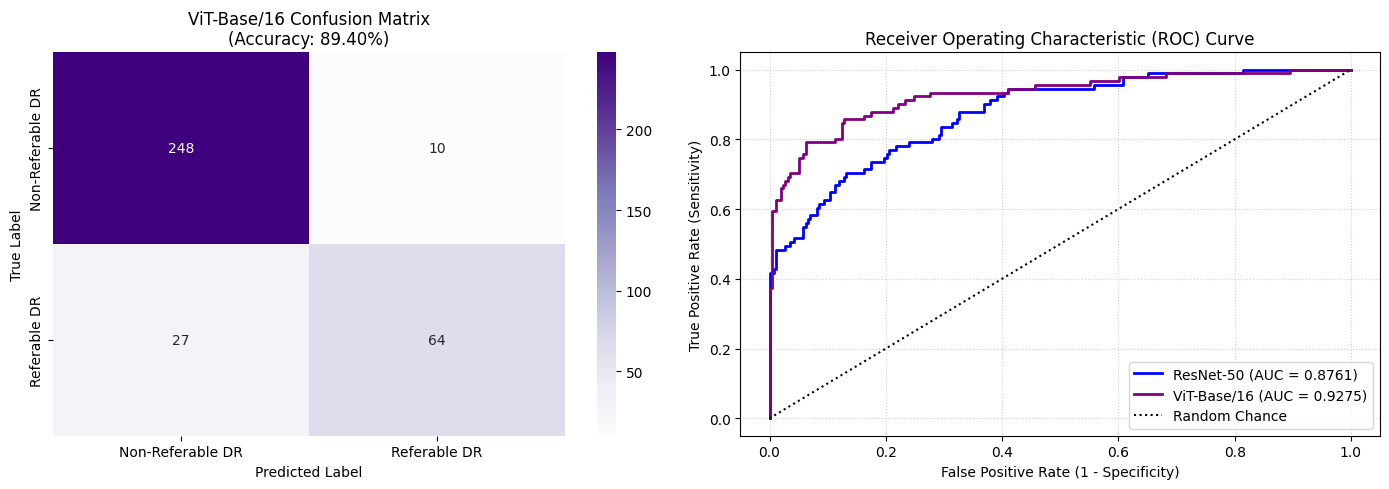

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# 1. Extract predictions, true labels, and probabilities
def get_eval_data(model, dataloader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

cnn_preds, true_labels, cnn_probs = get_eval_data(cnn_model, dataloaders['val'])
vit_preds, _, vit_probs = get_eval_data(vit_model, dataloaders['val'])

# 2. Performance Metrics Calculation
cnn_auc = roc_auc_score(true_labels, cnn_probs)
vit_auc = roc_auc_score(true_labels, vit_probs)

cnn_acc = np.mean(cnn_preds == true_labels)
vit_acc = np.mean(vit_preds == true_labels)

# Confusion Matrices & Sensitivity/Specificity
cm_cnn = confusion_matrix(true_labels, cnn_preds)
cm_vit = confusion_matrix(true_labels, vit_preds)

tn_c, fp_c, fn_c, tp_c = cm_cnn.ravel()
sens_cnn = tp_c / (tp_c + fn_c)
spec_cnn = tn_c / (tn_c + fp_c)

tn_v, fp_v, fn_v, tp_v = cm_vit.ravel()
sens_vit = tp_v / (tp_v + fn_v)
spec_vit = tn_v / (tn_v + fp_v)

print("="*65)
print("FINAL PUBLICATION EVALUATION METRICS (REFERABLE DR)")
print("="*65)
print(f"ResNet-50-HighAcc  | Acc: {cnn_acc:.4f} | AUC: {cnn_auc:.4f} | Sens: {sens_cnn:.4f} | Spec: {spec_cnn:.4f}")
print(f"ViT-Base/16-HighAcc| Acc: {vit_acc:.4f} | AUC: {vit_auc:.4f} | Sens: {sens_vit:.4f} | Spec: {spec_vit:.4f}")
print("="*65)

# Detailed Classification Reports
target_names = ['Non-Referable DR', 'Referable DR']
print("\n--- ResNet-50 Classification Report ---")
print(classification_report(true_labels, cnn_preds, target_names=target_names))

print("\n--- ViT-Base/16 Classification Report ---")
print(classification_report(true_labels, vit_preds, target_names=target_names))

# 3. Plot Confusion Matrices & ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Side-by-Side Confusion Matrices
sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title(f'ViT-Base/16 Confusion Matrix\n(Accuracy: {vit_acc*100:.2f}%)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Subplot 2: ROC Curves
fpr_c, tpr_c, _ = roc_curve(true_labels, cnn_probs)
fpr_v, tpr_v, _ = roc_curve(true_labels, vit_probs)

axes[1].plot(fpr_c, tpr_c, label=f'ResNet-50 (AUC = {cnn_auc:.4f})', color='blue', linewidth=2)
axes[1].plot(fpr_v, tpr_v, label=f'ViT-Base/16 (AUC = {vit_auc:.4f})', color='purple', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', linestyle=':', label='Random Chance')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("publication_evaluation_results.png", dpi=300)
plt.show()

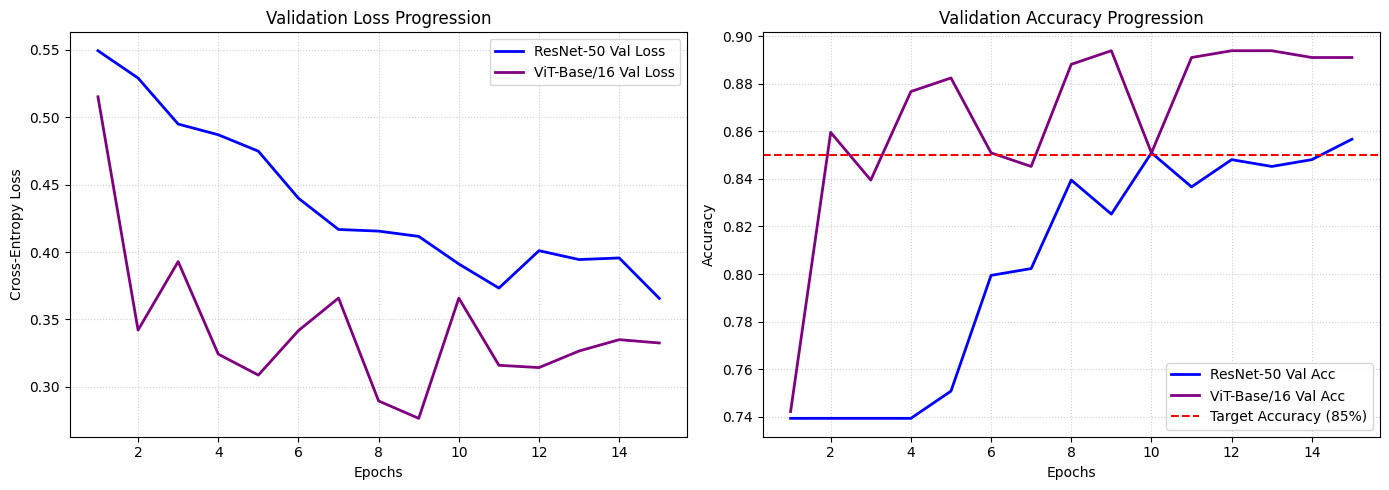

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
epochs_range = range(1, 16)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, cnn_history['val_loss'], label='ResNet-50 Val Loss', color='blue', linewidth=2)
plt.plot(epochs_range, vit_history['val_loss'], label='ViT-Base/16 Val Loss', color='purple', linewidth=2)
plt.title('Validation Loss Progression')
plt.xlabel('Epochs')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, cnn_history['val_acc'], label='ResNet-50 Val Acc', color='blue', linewidth=2)
plt.plot(epochs_range, vit_history['val_acc'], label='ViT-Base/16 Val Acc', color='purple', linewidth=2)
plt.axhline(y=0.85, color='red', linestyle='--', label='Target Accuracy (85%)')
plt.title('Validation Accuracy Progression')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("final_accuracy_loss_curves.png", dpi=300)
plt.show()

from google.colab import files
files.download("publication_evaluation_results.png")
files.download("final_accuracy_loss_curves.png")

In [ ]:
import torch
from google.colab import files

# Save trained weight checkpoints
torch.save(cnn_model.state_dict(), 'resnet50_referable_dr.pth')
torch.save(vit_model.state_dict(), 'vit_base_referable_dr.pth')

print("Model weights saved locally in Colab environment!")

# Optional: Download weight files to your computer
files.download('resnet50_referable_dr.pth')
files.download('vit_base_referable_dr.pth')

Model weights saved locally in Colab environment!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>